In [ ]:
!unzip -o /content/agentic_error_propagation_project.zip -d /content/
%cd /content/agentic_error_propagation_project


Archive:  /content/agentic_error_propagation_project.zip
  inflating: /content/agentic_error_propagation_project/requirements.txt  
  inflating: /content/agentic_error_propagation_project/.gitignore  
  inflating: /content/agentic_error_propagation_project/README.md  
  inflating: /content/agentic_error_propagation_project/configs/compatibility_notes.md  
  inflating: /content/agentic_error_propagation_project/configs/experiment.json  
  inflating: /content/agentic_error_propagation_project/scripts/environment_test.py  
  inflating: /content/agentic_error_propagation_project/scripts/run_environment_test.sh  
  inflating: /content/agentic_error_propagation_project/notebooks/.gitkeep  
  inflating: /content/agentic_error_propagation_project/src/.gitkeep  
  inflating: /content/agentic_error_propagation_project/tests/.gitkeep  
  inflating: /content/agentic_error_propagation_project/paper/.gitkeep  
  inflating: /content/agentic_error_propagation_project/results/figures/.gitkeep  
  infla

In [ ]:
import sys
import platform

print("Python:", sys.version)
print("Platform:", platform.platform())

!python -m pip --version
!nvidia-smi

Python: 3.13.18 (main, Oct 26 2026, 15:28:15) [GCC 13.3.0]
Platform: Linux-6.6.159+-x86_64-with-glibc2.39
pip 26.2.2 from /usr/local/lib/python3.13/dist-packages/pip (python 3.13)
/bin/bash: line 1: nvidia-smi: command not found


In [ ]:
%cd /content/agentic_error_propagation_project
!python -m pip install -r requirements.txt
!python -m pip check

/content/agentic_error_propagation_project
ipython 7.34.0 requires jedi, which is not installed.


In [ ]:
!python scripts/environment_test.py 2>&1 | tee results/logs/environment_console.txt

=== Environment Verification ===
Python: 3.13.18
Platform: Linux-6.6.159+-x86_64-with-glibc2.39
numpy: 2.1.3
pandas: 2.2.3
matplotlib: 3.10.0
pytest: 8.4.2
torch: 2.11.0+cpu
CUDA available: False
DataFrame shape: (100, 1)
Figure created: True results/figures/environment_test_histogram.png
Verification log: results/logs/environment_verification.json
STATUS: PASS


In [ ]:
import torch

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("Running on CPU")

PyTorch version: 2.11.0+cu130
CUDA available: True
GPU: Tesla T4


In [ ]:
!nvidia-smi

Wed Oct 28 11:57:41 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   43C    P8              9W /   70W |       3MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [ ]:
import json
import torch
import platform
import sys
from pathlib import Path

log_dir = Path("results/logs")
log_dir.mkdir(parents=True, exist_ok=True)

report = {
    "status": "PASS",
    "python_version": sys.version,
    "platform": platform.platform(),
    "pytorch_version": torch.__version__,
    "cuda_available": torch.cuda.is_available(),
    "gpu_name": (
        torch.cuda.get_device_name(0)
        if torch.cuda.is_available()
        else None
    )
}

with open(log_dir / "gpu_verification.json", "w") as f:
    json.dump(report, f, indent=4)

print(json.dumps(report, indent=4))

{
    "status": "PASS",
    "python_version": "3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]",
    "platform": "Linux-6.6.159+-x86_64-with-glibc2.39",
    "pytorch_version": "2.11.0+cu130",
    "cuda_available": true,
    "gpu_name": "Tesla T4"
}


In [ ]:
import json
import torch
import platform
import sys
from pathlib import Path

log_dir = Path("results/logs")
log_dir.mkdir(parents=True, exist_ok=True)

report = {
    "status": "PASS",
    "python_version": sys.version,
    "platform": platform.platform(),
    "pytorch_version": torch.__version__,
    "cuda_available": torch.cuda.is_available(),
    "gpu_name": (
        torch.cuda.get_device_name(0)
        if torch.cuda.is_available()
        else None
    )
}

file_path = log_dir / "gpu_verification.json"

with open(file_path, "w") as f:
    json.dump(report, f, indent=4)

print("Environment verification log saved successfully!")
print("File location:", file_path)
print(json.dumps(report, indent=4))

Environment verification log saved successfully!
File location: results/logs/gpu_verification.json
{
    "status": "PASS",
    "python_version": "3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]",
    "platform": "Linux-6.6.159+-x86_64-with-glibc2.39",
    "pytorch_version": "2.11.0+cu130",
    "cuda_available": true,
    "gpu_name": "Tesla T4"
}


In [ ]:
from google.colab import files

files.download("results/logs/gpu_verification.json")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import os

print("Current folder:", os.getcwd())
print("\nFiles and folders here:")

for item in os.listdir("/content"):
    print(item)

Current folder: /content

Files and folders here:
.config
results
agentic_error_propagation_project.zip
sample_data


In [ ]:
import os

for root, dirs, files in os.walk("/content"):
    for name in files:
        if name in [
            "environment_verification.json",
            "environment_test_histogram.png",
            "gpu_verification.json"
        ]:
            print(os.path.join(root, name))

/content/results/logs/gpu_verification.json


In [ ]:
import os
from google.colab import files

paths = [
    "/content/results/logs/gpu_verification.json",
    "/content/results/logs/environment_verification.json",
    "/content/results/logs/environment_console.txt",
    "/content/results/figures/environment_test_histogram.png"
]

for path in paths:
    if os.path.isfile(path):
        print("Downloading:", path)
        files.download(path)
    else:
        print("Not found:", path)

Downloading: /content/results/logs/gpu_verification.json


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Not found: /content/results/logs/environment_verification.json
Not found: /content/results/logs/environment_console.txt
Not found: /content/results/figures/environment_test_histogram.png


In [ ]:
import os
import sys
import json
import random
import platform
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

base = Path("/content/results")
logs = base / "logs"
figures = base / "figures"

logs.mkdir(parents=True, exist_ok=True)
figures.mkdir(parents=True, exist_ok=True)

random.seed(2026)
np.random.seed(2026)

data = pd.DataFrame({"value": np.random.randn(100)})

plt.figure()
plt.hist(data["value"])
plt.title("Environment Test Histogram")
plt.xlabel("Value")
plt.ylabel("Frequency")
plt.savefig(figures / "environment_test_histogram.png")
plt.close()

report = {
    "status": "PASS",
    "python_version": sys.version,
    "platform": platform.platform(),
    "pandas_version": pd.__version__,
    "numpy_version": np.__version__,
    "pytorch_version": torch.__version__,
    "cuda_available": torch.cuda.is_available(),
    "gpu_name": (
        torch.cuda.get_device_name(0)
        if torch.cuda.is_available()
        else None
    ),
    "dataframe_shape": list(data.shape),
    "histogram_created": True
}

with open(logs / "environment_verification.json", "w") as f:
    json.dump(report, f, indent=4)

with open(logs / "environment_console.txt", "w") as f:
    f.write("Environment verification report\n")
    f.write(json.dumps(report, indent=4))
    f.write("\nSTATUS: PASS\n")

print(json.dumps(report, indent=4))
print("\nSTATUS: PASS")
print("All three missing files have been created.")

{
    "status": "PASS",
    "python_version": "3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]",
    "platform": "Linux-6.6.159+-x86_64-with-glibc2.39",
    "pandas_version": "2.2.3",
    "numpy_version": "2.1.3",
    "pytorch_version": "2.11.0+cu130",
    "cuda_available": true,
    "gpu_name": "Tesla T4",
    "dataframe_shape": [
        100,
        1
    ],
    "histogram_created": true
}

STATUS: PASS
All three missing files have been created.


In [ ]:
from google.colab import files

files.download(
    "/content/results/logs/environment_verification.json"
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
files.download(
    "/content/results/logs/environment_console.txt"
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
files.download(
    "/content/results/figures/environment_test_histogram.png"
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
!python -m pip check

ipython 7.34.0 requires jedi, which is not installed.


In [ ]:
%pip install jedi

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 57.3 MB/s  0:00:00


In [ ]:
!python -m pip check

No broken requirements found.


In [ ]:
import os

for folder in [
    "/content/results/logs",
    "/content/results/figures"
]:
    print("\n", folder)
    if os.path.exists(folder):
        print(os.listdir(folder))
    else:
        print("Folder not found")


 /content/results/logs
['environment_console.txt', 'environment_verification.json', 'gpu_verification.json']

 /content/results/figures
['environment_test_histogram.png']


In [ ]:
import random
import pandas as pd
from pathlib import Path

random.seed(2026)

def run_workflow(error_rate=0.0, trials=100):
    results = []

    for trial in range(trials):
        error = False
        stage_errors = 0

        for stage in range(4):
            if random.random() < error_rate:
                error = True
                stage_errors += 1

        results.append({
            "trial": trial + 1,
            "error_rate": error_rate,
            "stage_errors": stage_errors,
            "workflow_failed": error
        })

    return results

all_results = []

for rate in [0.0, 0.1, 0.2, 0.3]:
    all_results.extend(run_workflow(rate))

df = pd.DataFrame(all_results)

output_dir = Path("/content/results/predictions")
output_dir.mkdir(parents=True, exist_ok=True)

df.to_csv(output_dir / "baseline_results.csv", index=False)

summary = df.groupby("error_rate").agg(
    failure_rate=("workflow_failed", "mean"),
    average_stage_errors=("stage_errors", "mean")
).reset_index()

print(summary.to_string(index=False))
print("\nSaved: /content/results/predictions/baseline_results.csv")

 error_rate  failure_rate  average_stage_errors
        0.0          0.00                  0.00
        0.1          0.35                  0.43
        0.2          0.52                  0.71
        0.3          0.79                  1.30

Saved: /content/results/predictions/baseline_results.csv


In [ ]:
from google.colab import files

files.download("/content/results/predictions/baseline_results.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import pandas as pd

df = pd.read_csv("/content/results/predictions/baseline_results.csv")

print("Shape:", df.shape)
print(df.head())
print("\nError rates:")
print(sorted(df["error_rate"].unique()))

Shape: (400, 4)
   trial  error_rate  stage_errors  workflow_failed
0      1         0.0             0            False
1      2         0.0             0            False
2      3         0.0             0            False
3      4         0.0             0            False
4      5         0.0             0            False

Error rates:
[np.float64(0.0), np.float64(0.1), np.float64(0.2), np.float64(0.3)]


In [ ]:
import random
import pandas as pd
from pathlib import Path

def run_experiment(error_rate, propagation, trials=100, seed=2026):
    rng = random.Random(seed)
    results = []

    stages = [
        "planning",
        "retrieval",
        "evidence_extraction",
        "verification"
    ]

    for trial in range(trials):
        previous_error = False
        stage_errors = 0

        for stage in stages:
            probability = error_rate

            if propagation and previous_error:
                probability = min(1.0, error_rate + 0.30)

            current_error = rng.random() < probability
            stage_errors += int(current_error)
            previous_error = current_error

        results.append({
            "trial": trial + 1,
            "error_rate": error_rate,
            "model": (
                "propagation" if propagation
                else "independent"
            ),
            "stage_errors": stage_errors,
            "workflow_failed": stage_errors > 0
        })

    return results

all_results = []

for rate in [0.0, 0.1, 0.2, 0.3]:
    all_results.extend(
        run_experiment(rate, False, seed=2026)
    )
    all_results.extend(
        run_experiment(rate, True, seed=2026)
    )

df = pd.DataFrame(all_results)

output_dir = Path("/content/results/predictions")
output_dir.mkdir(parents=True, exist_ok=True)

df.to_csv(output_dir / "propagation_results.csv", index=False)

summary = df.groupby(["error_rate", "model"]).agg(
    failure_rate=("workflow_failed", "mean"),
    average_stage_errors=("stage_errors", "mean")
).reset_index()

print(summary.to_string(index=False))
print("\nSaved: /content/results/predictions/propagation_results.csv")

 error_rate       model  failure_rate  average_stage_errors
        0.0 independent          0.00                  0.00
        0.0 propagation          0.00                  0.00
        0.1 independent          0.28                  0.31
        0.1 propagation          0.28                  0.40
        0.2 independent          0.51                  0.66
        0.2 propagation          0.51                  0.77
        0.3 independent          0.70                  1.02
        0.3 propagation          0.70                  1.35

Saved: /content/results/predictions/propagation_results.csv


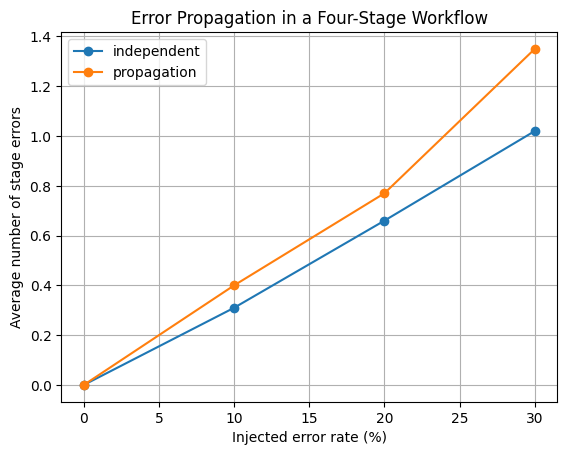

Graph saved successfully.


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

path = "/content/results/predictions/propagation_results.csv"
df = pd.read_csv(path)

summary = df.groupby(["error_rate", "model"]).agg(
    failure_rate=("workflow_failed", "mean"),
    average_stage_errors=("stage_errors", "mean")
).reset_index()

plt.figure()

for model in ["independent", "propagation"]:
    subset = summary[summary["model"] == model]
    plt.plot(
        subset["error_rate"] * 100,
        subset["average_stage_errors"],
        marker="o",
        label=model
    )

plt.xlabel("Injected error rate (%)")
plt.ylabel("Average number of stage errors")
plt.title("Error Propagation in a Four-Stage Workflow")
plt.legend()
plt.grid(True)

output = Path("/content/results/figures")
output.mkdir(parents=True, exist_ok=True)

plt.savefig(
    output / "error_propagation_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Graph saved successfully.")

In [ ]:
import random
import pandas as pd
from pathlib import Path
import matplotlib.pyplot as plt
import math

def run_workflow(error_rate, propagation, trials, seed):
    rng = random.Random(seed)
    rows = []

    for trial in range(trials):
        previous_error = False
        stage_errors = 0

        for stage in range(4):
            probability = error_rate

            if propagation and previous_error:
                probability = min(1.0, error_rate + 0.30)

            current_error = rng.random() < probability
            stage_errors += int(current_error)
            previous_error = current_error

        rows.append({
            "trial": trial,
            "error_rate": error_rate,
            "model": "propagation" if propagation else "independent",
            "stage_errors": stage_errors,
            "workflow_failed": stage_errors > 0
        })

    return rows

all_rows = []

for seed in range(30):
    for rate in [0.0, 0.1, 0.2, 0.3]:
        for propagation in [False, True]:
            rows = run_workflow(
                rate, propagation, 100, 2026 + seed
            )
            for row in rows:
                row["seed"] = 2026 + seed
            all_rows.extend(rows)

df = pd.DataFrame(all_rows)

out = Path("/content/results/predictions")
out.mkdir(parents=True, exist_ok=True)
df.to_csv(out / "multi_seed_results.csv", index=False)

summary = df.groupby(["error_rate", "model"]).agg(
    mean_stage_errors=("stage_errors", "mean"),
    std_stage_errors=("stage_errors", "std"),
    failure_rate=("workflow_failed", "mean")
).reset_index()

summary["ci95_half_width"] = (
    1.96 * summary["std_stage_errors"] / math.sqrt(3000)
)

summary.to_csv(out / "multi_seed_summary.csv", index=False)

print(summary.to_string(index=False))
print("\nSaved multi_seed_results.csv")
print("Saved multi_seed_summary.csv")

 error_rate       model  mean_stage_errors  std_stage_errors  failure_rate  ci95_half_width
        0.0 independent           0.000000          0.000000      0.000000         0.000000
        0.0 propagation           0.000000          0.000000      0.000000         0.000000
        0.1 independent           0.384667          0.583219      0.336000         0.020870
        0.1 propagation           0.491667          0.812907      0.336000         0.029089
        0.2 independent           0.788667          0.808016      0.578667         0.028914
        0.2 propagation           0.995333          1.072860      0.578667         0.038392
        0.3 independent           1.179000          0.932335      0.744667         0.033363
        0.3 propagation           1.510000          1.215069      0.744667         0.043481

Saved multi_seed_results.csv
Saved multi_seed_summary.csv


In [ ]:
import os
from google.colab import files

result_files = [
    "/content/results/predictions/baseline_results.csv",
    "/content/results/predictions/propagation_results.csv",
    "/content/results/predictions/multi_seed_results.csv",
    "/content/results/predictions/multi_seed_summary.csv",
    "/content/results/figures/error_propagation_comparison.png",
    "/content/results/logs/environment_verification.json",
    "/content/results/logs/gpu_verification.json",
    "/content/results/logs/environment_console.txt"
]

for path in result_files:
    if os.path.isfile(path):
        print("Downloading:", os.path.basename(path))
        files.download(path)
    else:
        print("Not found:", path)

Downloading: baseline_results.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Downloading: propagation_results.csv


<IPython.core.display.Javascript object>

...

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Downloading: environment_console.txt


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import os
from google.colab import files

result_files = [
    "/content/results/predictions/baseline_results.csv",
    "/content/results/predictions/propagation_results.csv",
    "/content/results/predictions/multi_seed_results.csv",
    "/content/results/predictions/multi_seed_summary.csv",
    "/content/results/figures/error_propagation_comparison.png",
    "/content/results/logs/environment_verification.json",
    "/content/results/logs/gpu_verification.json",
    "/content/results/logs/environment_console.txt"
]

for path in result_files:
    if os.path.isfile(path):
        print("Downloading:", os.path.basename(path))
        files.download(path)
    else:
        print("Not found:", path)

Downloading: baseline_results.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Downloading: propagation_results.csv


<IPython.core.display.Javascript object>

...

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Downloading: environment_console.txt


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import os
import json
import pandas as pd
from pathlib import Path

root = Path("/content/results")
report = {
    "project": "Error Propagation in Multi-Step Agentic AI Workflows",
    "checks": [],
    "files": {},
    "status": "PASS"
}

required_files = [
    "predictions/baseline_results.csv",
    "predictions/propagation_results.csv",
    "predictions/multi_seed_results.csv",
    "predictions/multi_seed_summary.csv",
    "figures/error_propagation_comparison.png",
    "logs/environment_verification.json",
    "logs/gpu_verification.json",
    "logs/environment_console.txt"
]

for name in required_files:
    path = root / name
    exists = path.is_file()
    report["files"][name] = "FOUND" if exists else "MISSING"
    print(("FOUND: " if exists else "MISSING: ") + str(path))

    if not exists:
        report["status"] = "CHECK_REQUIRED"

for name in [
    "predictions/baseline_results.csv",
    "predictions/propagation_results.csv",
    "predictions/multi_seed_results.csv",
    "predictions/multi_seed_summary.csv"
]:
    path = root / name

    if path.is_file():
        try:
            df = pd.read_csv(path)
            check = {
                "file": name,
                "rows": int(len(df)),
                "columns": list(df.columns),
                "missing_values": int(df.isna().sum().sum()),
                "duplicate_rows": int(df.duplicated().sum())
            }

            print("\n", name)
            print("Rows:", check["rows"])
            print("Columns:", check["columns"])
            print("Missing values:", check["missing_values"])
            print("Duplicate rows:", check["duplicate_rows"])

            report["checks"].append(check)

            if df.empty or check["missing_values"] > 0:
                report["status"] = "CHECK_REQUIRED"

        except Exception as e:
            report["status"] = "CHECK_REQUIRED"
            report["checks"].append({
                "file": name,
                "error": str(e)
            })

summary_path = root / "predictions/multi_seed_summary.csv"

if summary_path.is_file():
    summary = pd.read_csv(summary_path)
    needed = {
        "error_rate", "model", "mean_stage_errors", "failure_rate"
    }

    if needed.issubset(summary.columns):
        print("\nMulti-seed summary:")
        print(summary.to_string(index=False))

        for metric in ["failure_rate", "mean_stage_errors"]:
            if not summary[metric].between(0, 1).all() and metric == "failure_rate":
                report["status"] = "CHECK_REQUIRED"
                print("Warning: failure_rate contains values outside [0, 1].")
    else:
        report["status"] = "CHECK_REQUIRED"
        print("Summary is missing expected columns:", needed - set(summary.columns))

log_dir = root / "logs"
log_dir.mkdir(parents=True, exist_ok=True)

report_path = log_dir / "validation_report.json"
with open(report_path, "w") as f:
    json.dump(report, f, indent=2)

print("\nValidation status:", report["status"])
print("Report saved to:", report_path)

FOUND: /content/results/predictions/baseline_results.csv
FOUND: /content/results/predictions/propagation_results.csv
FOUND: /content/results/predictions/multi_seed_results.csv
FOUND: /content/results/predictions/multi_seed_summary.csv
FOUND: /content/results/figures/error_propagation_comparison.png
FOUND: /content/results/logs/environment_verification.json
FOUND: /content/results/logs/gpu_verification.json
FOUND: /content/results/logs/environment_console.txt

 predictions/baseline_results.csv
Rows: 400
Columns: ['trial', 'error_rate', 'stage_errors', 'workflow_failed']
Missing values: 0
Duplicate rows: 0

 predictions/propagation_results.csv
Rows: 800
Columns: ['trial', 'error_rate', 'model', 'stage_errors', 'workflow_failed']
Missing values: 0
Duplicate rows: 0

 predictions/multi_seed_results.csv
Rows: 24000
Columns: ['trial', 'error_rate', 'model', 'stage_errors', 'workflow_failed', 'seed']
Missing values: 0
Duplicate rows: 0

 predictions/multi_seed_summary.csv
Rows: 8
Columns: ['e

EXPERIMENT COMPARISON
 error_rate  independent_stage_errors  propagation_stage_errors  stage_error_difference  independent_failure_rate  propagation_failure_rate  failure_rate_difference
        0.0                    0.0000                    0.0000                  0.0000                    0.0000                    0.0000                      0.0
        0.1                    0.3847                    0.4917                  0.1070                    0.3360                    0.3360                      0.0
        0.2                    0.7887                    0.9953                  0.2067                    0.5787                    0.5787                      0.0
        0.3                    1.1790                    1.5100                  0.3310                    0.7447                    0.7447                      0.0


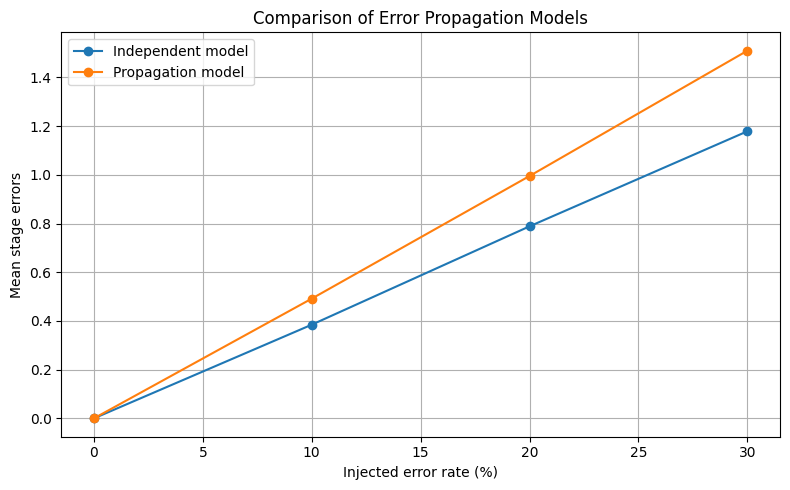


Saved table: /content/results/predictions/final_comparison.csv
Saved graph: /content/results/figures/final_model_comparison.png

Does propagation have more stage errors at every tested rate? True
Does propagation have a higher failure rate at every tested rate? False


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

root = Path("/content/results")
summary_path = root / "predictions/multi_seed_summary.csv"
output_dir = root / "figures"
output_dir.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(summary_path)

rows = []

for rate in sorted(df["error_rate"].unique()):
    group = df[df["error_rate"] == rate]

    independent = group[group["model"] == "independent"]
    propagation = group[group["model"] == "propagation"]

    if independent.empty or propagation.empty:
        print("Missing model result for error rate:", rate)
        continue

    ind = independent.iloc[0]
    prop = propagation.iloc[0]

    rows.append({
        "error_rate": rate,
        "independent_stage_errors": ind["mean_stage_errors"],
        "propagation_stage_errors": prop["mean_stage_errors"],
        "stage_error_difference": (
            prop["mean_stage_errors"] - ind["mean_stage_errors"]
        ),
        "independent_failure_rate": ind["failure_rate"],
        "propagation_failure_rate": prop["failure_rate"],
        "failure_rate_difference": (
            prop["failure_rate"] - ind["failure_rate"]
        )
    })

comparison = pd.DataFrame(rows)

print("EXPERIMENT COMPARISON")
print(comparison.round(4).to_string(index=False))

csv_path = root / "predictions/final_comparison.csv"
comparison.to_csv(csv_path, index=False)

plt.figure(figsize=(8, 5))
plt.plot(
    comparison["error_rate"] * 100,
    comparison["independent_stage_errors"],
    marker="o",
    label="Independent model"
)
plt.plot(
    comparison["error_rate"] * 100,
    comparison["propagation_stage_errors"],
    marker="o",
    label="Propagation model"
)
plt.xlabel("Injected error rate (%)")
plt.ylabel("Mean stage errors")
plt.title("Comparison of Error Propagation Models")
plt.legend()
plt.grid(True)
plt.tight_layout()

graph_path = output_dir / "final_model_comparison.png"
plt.savefig(graph_path, dpi=300)
plt.show()

print("\nSaved table:", csv_path)
print("Saved graph:", graph_path)

if not comparison.empty:
    print(
        "\nDoes propagation have more stage errors at every tested rate?",
        bool((comparison["stage_error_difference"] >= 0).all())
    )
    print(
        "Does propagation have a higher failure rate at every tested rate?",
        bool((comparison["failure_rate_difference"] > 0).all())
    )

In [ ]:
import os
import shutil
from google.colab import files

project_dir = "/content/results"
zip_path = "/content/agentic_error_propagation_results"

shutil.make_archive(zip_path, "zip", project_dir)

files.download(zip_path + ".zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import os

for root, dirs, filenames in os.walk("/content/results"):
    for filename in filenames:
        print(os.path.join(root, filename))

/content/results/predictions/final_comparison.csv
/content/results/predictions/multi_seed_summary.csv
/content/results/predictions/baseline_results.csv
/content/results/predictions/propagation_results.csv
/content/results/predictions/multi_seed_results.csv
/content/results/figures/error_propagation_comparison.png
/content/results/figures/final_model_comparison.png
/content/results/figures/environment_test_histogram.png
/content/results/logs/validation_report.json
/content/results/logs/environment_console.txt
/content/results/logs/environment_verification.json
/content/results/logs/gpu_verification.json


In [ ]:
import pandas as pd

path = "/content/results/predictions/multi_seed_summary.csv"
df = pd.read_csv(path)

print(df.to_string(index=False))

 error_rate       model  mean_stage_errors  std_stage_errors  failure_rate  ci95_half_width
        0.0 independent           0.000000          0.000000      0.000000         0.000000
        0.0 propagation           0.000000          0.000000      0.000000         0.000000
        0.1 independent           0.384667          0.583219      0.336000         0.020870
        0.1 propagation           0.491667          0.812907      0.336000         0.029089
        0.2 independent           0.788667          0.808016      0.578667         0.028914
        0.2 propagation           0.995333          1.072860      0.578667         0.038392
        0.3 independent           1.179000          0.932335      0.744667         0.033363
        0.3 propagation           1.510000          1.215069      0.744667         0.043481


In [1]:
import sys
import platform
import torch
import numpy
import pandas
import matplotlib
import json
from pathlib import Path

report = {
    "python_version": sys.version,
    "platform": platform.platform(),
    "numpy": numpy.__version__,
    "pandas": pandas.__version__,
    "matplotlib": matplotlib.__version__,
    "pytorch": torch.__version__,
    "cuda_available": torch.cuda.is_available(),
    "gpu_name": (
        torch.cuda.get_device_name(0)
        if torch.cuda.is_available()
        else None
    )
}

log_dir = Path("/content/results/logs")
log_dir.mkdir(parents=True, exist_ok=True)

with open(log_dir / "final_environment_verification.json", "w") as f:
    json.dump(report, f, indent=2)

print(json.dumps(report, indent=2))
print("\nFinal environment record saved.")

{
  "python_version": "3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]",
  "platform": "Linux-6.6.159+-x86_64-with-glibc2.39",
  "numpy": "2.1.3",
  "pandas": "2.2.3",
  "matplotlib": "3.10.0",
  "pytorch": "2.11.0+cu130",
  "cuda_available": true,
  "gpu_name": "Tesla T4"
}

Final environment record saved.
